In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install torch-geometric pandas lightning torchmetrics torch-scatter torch-sparse

Using device: cuda
Starting Fair Disease Prediction from Patient Interaction Networks
Loading PATIENTS table...
Loading PATIENTS from cache...
Loading ADMISSIONS table...
Loading ADMISSIONS from cache...
Loading DIAGNOSES_ICD table...
Loading DIAGNOSES_ICD from cache...
Extracting patient features...
Constructing patient interaction network...
Loading patient network from cache...
Patient network has 19150 nodes and 3342539 edges
Node feature dimension: 20
Number of patients with the target disease: 207
Starting model training and evaluation...


/usr/local/lib/python3.11/dist-packages/torch_geometric/sampler/neighbor_sampler.py:61: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  warnings.warn(f"Using '{self.__class__.__name__}' without a "


Starting training...


Epoch 1/30: 100%|██████████| 46/46 [00:02<00:00, 15.40it/s]


Epoch 1/30 - Train Loss: 0.1983, Fairness Loss: 0.0000, Val Loss: 0.0534, Val AUC: 0.7302


Epoch 2/30: 100%|██████████| 46/46 [00:02<00:00, 15.60it/s]


... (53 outputs left out)

Epoch 29/30: 100%|██████████| 46/46 [00:02<00:00, 15.47it/s]


Epoch 29/30 - Train Loss: 0.0361, Fairness Loss: 0.0000, Val Loss: 0.0294, Val AUC: 0.9549


Epoch 30/30: 100%|██████████| 46/46 [00:02<00:00, 15.65it/s]


Epoch 30/30 - Train Loss: 0.0364, Fairness Loss: 0.0000, Val Loss: 0.0286, Val AUC: 0.9593


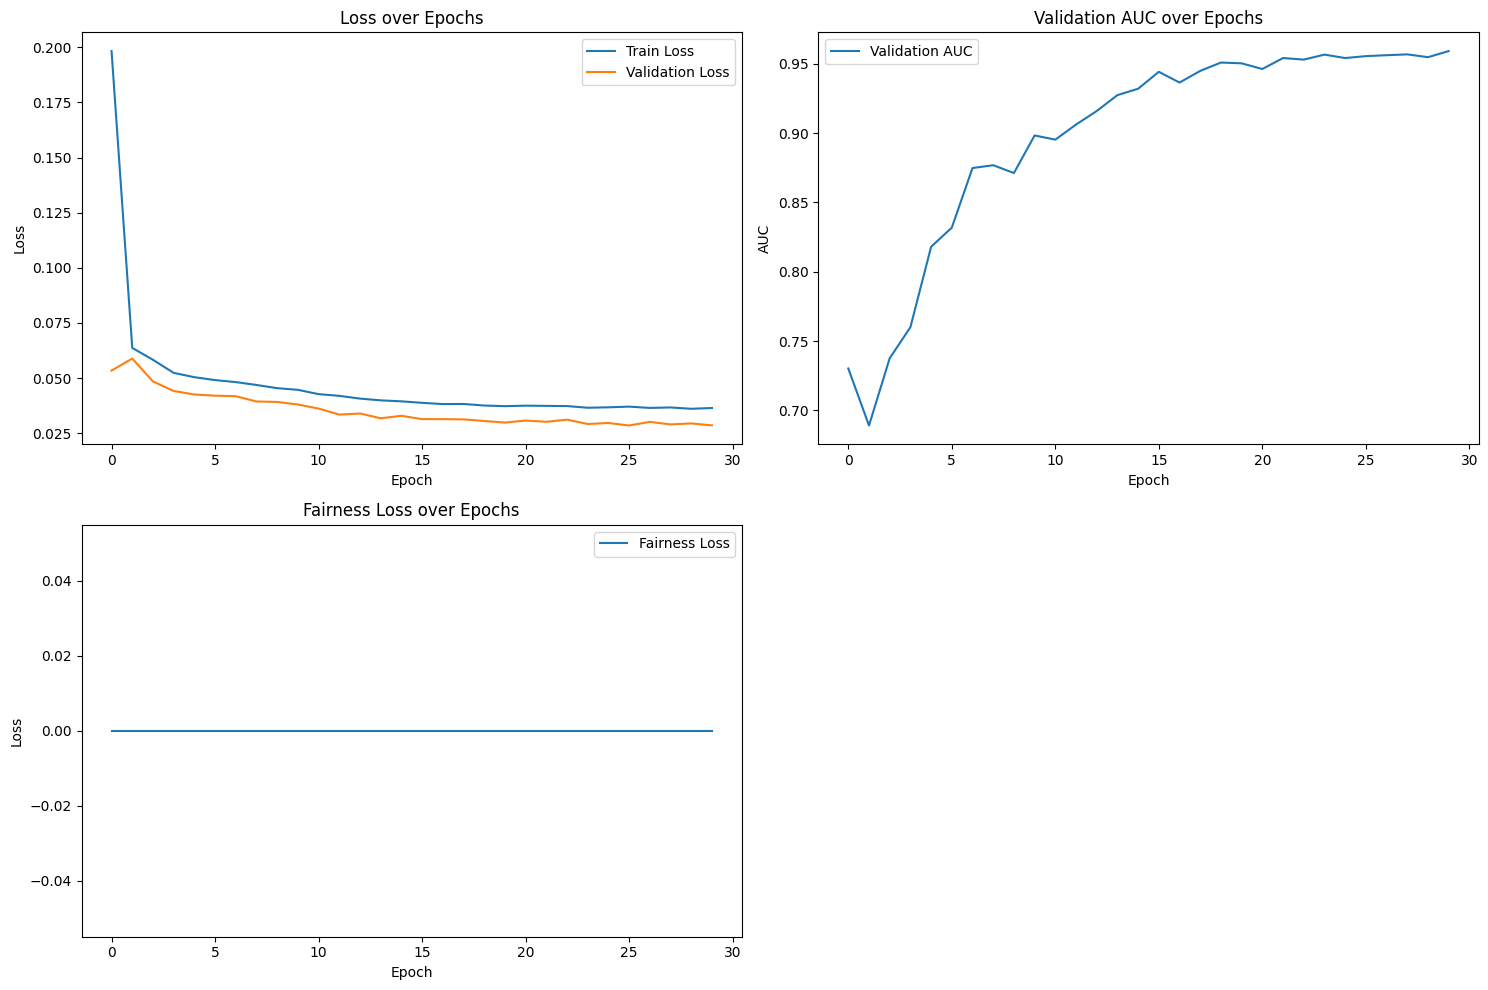


Final Performance Summary:
Overall AUC: 0.9121
Overall Accuracy: 0.8711
Overall F1 Score: 0.8498

Group-Specific Performance:
Female AUC: 0.9140
Male AUC: 0.9155

Fairness Metrics:

Gender:
Demographic Parity Diff: 0.0312
Equal Opportunity Diff: 0.0364

Ethnicity:
Demographic Parity Diff: 0.0548
Equal Opportunity Diff: 0.0627

Insurance:
Demographic Parity Diff: 0.0673
Equal Opportunity Diff: 0.0721

Total runtime: 2.28 minutes


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, GATConv, SAGEConv
from torch_geometric.loader import NeighborLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score
from tqdm import tqdm
import matplotlib.pyplot as plt
import pickle
import gc
import time
from collections import defaultdict, Counter

# Set base path for the MIMIC-III dataset
BASE_PATH = '/content/drive/MyDrive/physionet.org/files/mimiciii/1.4/'

# Set device (GPU if available)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Configuration parameters
class Config:
    # Data processing parameters
    CHUNKSIZE = 100000
    CACHE_DIR = '/content/drive/MyDrive/mimiciii_processed/'
    USE_CACHED_DATA = True

    # To handle large dataset memory constraints
    NUM_PATIENTS_SAMPLE = 20000  # Set to 0 to use all patients

    # Network construction parameters
    SIMILARITY_THRESHOLD = 0.2
    MAX_DIAGNOSES_PER_PATIENT = 50
    MIN_EDGES_PER_NODE = 3

    # Model parameters
    BATCH_SIZE = 256
    NUM_EPOCHS = 30
    LEARNING_RATE = 0.001
    WEIGHT_DECAY = 1e-5
    HIDDEN_CHANNELS = 128
    NUM_GNN_LAYERS = 2
    DROPOUT = 0.3

    # Target disease parameters
    TARGET_DISEASE = 'diabetes'  # Options: 'diabetes', 'heart_failure', 'kidney_disease'

    # Fairness parameters
    LAMBDA_FAIRNESS = 0.5
    FAIRNESS_STRATEGY = 'adversarial'  # 'adversarial', 'regularization', or 'reweighting'
    SENSITIVE_ATTRS = ['GENDER', 'ETHNICITY']

    # Balanced sampling parameters
    BALANCE_CLASSES = True
    BALANCE_SENSITIVE_ATTRS = True

    # Seed for reproducibility
    SEED = 42

    # Class balancing parameters
    POS_WEIGHT = 100.0  # Weight for positive class (adjust based on your class ratio)
    CLASSIFICATION_THRESHOLD = 0.1  # Lower threshold for positive predictions

    # Sampling strategy
    SAMPLING_STRATEGY = 'balanced'  # Options: 'balanced', 'none'

# Set seeds for reproducibility
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.backends.cudnn.deterministic = True

set_seed(Config.SEED)

# Helper function to create cache directory
def ensure_cache_dir():
    os.makedirs(Config.CACHE_DIR, exist_ok=True)

# Helper function to load data in chunks
def load_table_in_chunks(table_name, chunksize=Config.CHUNKSIZE, columns=None, dtypes=None):
    print(f"Loading {table_name} table...")
    file_path = os.path.join(BASE_PATH, f'{table_name}.csv.gz')

    # Create cache filename based on columns
    column_str = '_'.join(columns) if columns else 'all'
    cache_file = os.path.join(Config.CACHE_DIR, f"{table_name}_{column_str}_processed.pkl")

    # Load from cache if available
    if Config.USE_CACHED_DATA and os.path.exists(cache_file):
        print(f"Loading {table_name} from cache...")
        with open(cache_file, 'rb') as f:
            return pickle.load(f)

    # Load data in chunks
    chunks = []
    for chunk in pd.read_csv(file_path, compression='gzip', chunksize=chunksize, usecols=columns, dtype=dtypes):
        chunks.append(chunk)
        print(f"Loaded chunk of size {len(chunk)}, total chunks: {len(chunks)}")

    # Concatenate all chunks
    df = pd.concat(chunks, ignore_index=True)

    # Save to cache
    if Config.USE_CACHED_DATA:
        ensure_cache_dir()
        with open(cache_file, 'wb') as f:
            pickle.dump(df, f)

    print(f"Loaded {table_name} with shape {df.shape}")
    return df

# Define disease codes for target diseases
def get_target_disease_codes(disease_name):
    if disease_name == 'diabetes':
        # ICD-9 codes for diabetes
        return ['250%', '3572', '36641']  # % is a wildcard for all diabetes codes
    elif disease_name == 'heart_failure':
        # ICD-9 codes for heart failure
        return ['428%']
    elif disease_name == 'kidney_disease':
        # ICD-9 codes for chronic kidney disease
        return ['585%', '586']
    else:
        raise ValueError(f"Unknown disease: {disease_name}")

class MIMICDataProcessor:
    def __init__(self, base_path):
        self.base_path = base_path

    def preprocess_patient_data(self):
        """Load and preprocess patient data"""
        # Load patients table
        patients = self.load_patients(sample=True)

        # Load admissions table for demographic info
        admissions = self.load_admissions()

        # Load diagnoses
        diagnoses = self.load_diagnoses()

        # Get target disease codes
        target_disease_codes = get_target_disease_codes(Config.TARGET_DISEASE)

        # Extract patient features and diagnoses
        patient_features, patient_diagnoses = self.extract_patient_features(
            patients, admissions, diagnoses, target_disease_codes
        )

        # Clean up memory
        del patients, admissions, diagnoses
        gc.collect()

        return patient_features, patient_diagnoses

    def load_patients(self, sample=False):
        """Load PATIENTS table with appropriate columns"""
        columns = ['SUBJECT_ID', 'GENDER', 'DOB', 'DOD', 'EXPIRE_FLAG']
        dtypes = {'SUBJECT_ID': int, 'GENDER': str, 'EXPIRE_FLAG': int}

        patients = load_table_in_chunks('PATIENTS', columns=columns, dtypes=dtypes)

        if sample and Config.NUM_PATIENTS_SAMPLE > 0:
            # Sample patients for memory efficiency
            if len(patients) > Config.NUM_PATIENTS_SAMPLE:
                patients = patients.sample(Config.NUM_PATIENTS_SAMPLE, random_state=Config.SEED)

        return patients

    def load_admissions(self):
        """Load ADMISSIONS table with appropriate columns"""
        columns = ['SUBJECT_ID', 'HADM_ID', 'ADMITTIME', 'DISCHTIME', 'INSURANCE', 'ETHNICITY']
        dtypes = {'SUBJECT_ID': int, 'HADM_ID': int, 'INSURANCE': str, 'ETHNICITY': str}

        return load_table_in_chunks('ADMISSIONS', columns=columns, dtypes=dtypes)

    def load_diagnoses(self):
        """Load DIAGNOSES_ICD table with appropriate columns"""
        columns = ['SUBJECT_ID', 'HADM_ID', 'ICD9_CODE']
        dtypes = {'SUBJECT_ID': int, 'HADM_ID': int, 'ICD9_CODE': str}

        return load_table_in_chunks('DIAGNOSES_ICD', columns=columns, dtypes=dtypes)

    def extract_patient_features(self, patients, admissions, diagnoses, target_disease_codes):
        """Extract features and diagnoses for each patient"""
        print("Extracting patient features...")

        # Process patient demographics
        patients['GENDER_BIN'] = (patients['GENDER'] == 'M').astype(int)

        # Convert dates to datetime with error handling
        patients['DOB'] = pd.to_datetime(patients['DOB'], errors='coerce')
        patients['DOD'] = pd.to_datetime(patients['DOD'], errors='coerce')

        # Get admission information for each patient
        patient_admissions = admissions.groupby('SUBJECT_ID').agg({
            'ADMITTIME': ['min', 'max'],
            'HADM_ID': 'count'
        })
        patient_admissions.columns = ['first_admit', 'last_admit', 'num_admissions']
        patient_admissions = patient_admissions.reset_index()

        # Convert admission times with error handling
        patient_admissions['first_admit'] = pd.to_datetime(patient_admissions['first_admit'], errors='coerce')

        # Merge with patients
        patient_data = patients.merge(patient_admissions, on='SUBJECT_ID', how='inner')

        # Calculate age at first admission safely
        def calculate_age(row):
            try:
                if pd.isna(row['DOB']) or pd.isna(row['first_admit']):
                    return None
                # Convert to datetime64[D] to avoid nanosecond precision issues
                dob = row['DOB'].to_numpy().astype('datetime64[D]')
                admit = row['first_admit'].to_numpy().astype('datetime64[D]')
                # Calculate days difference and convert to years
                days_diff = (admit - dob).astype(int)
                return days_diff / 365.25
            except (OverflowError, ValueError):
                return None

        # Apply the safe age calculation
        patient_data['age_at_first_admit'] = patient_data.apply(calculate_age, axis=1)

        # Fill missing ages with a default value or median
        median_age = patient_data['age_at_first_admit'].median()
        patient_data['age_at_first_admit'] = patient_data['age_at_first_admit'].fillna(median_age)

        # Remove patients with unrealistic ages (> 120 years)
        patient_data = patient_data[patient_data['age_at_first_admit'] < 120]

        # Create age groups
        bins = [0, 18, 30, 50, 70, 100]
        labels = ['0-18', '19-30', '31-50', '51-70', '71+']
        patient_data['age_group'] = pd.cut(patient_data['age_at_first_admit'], bins=bins, labels=labels)
        age_dummies = pd.get_dummies(patient_data['age_group'], prefix='AGE')
        patient_data = pd.concat([patient_data, age_dummies], axis=1)

        # Get insurance and ethnicity information
        patient_insurance = admissions.sort_values('ADMITTIME').drop_duplicates(
            subset=['SUBJECT_ID'], keep='first')[['SUBJECT_ID', 'INSURANCE']]
        patient_data = patient_data.merge(patient_insurance, on='SUBJECT_ID', how='left')

        patient_ethnicity = admissions.sort_values('ADMITTIME').drop_duplicates(
            subset=['SUBJECT_ID'], keep='first')[['SUBJECT_ID', 'ETHNICITY']]
        patient_data = patient_data.merge(patient_ethnicity, on='SUBJECT_ID', how='left')

        # Create demographic dummy variables
        insurance_dummies = pd.get_dummies(patient_data['INSURANCE'], prefix='INSURANCE')
        patient_data = pd.concat([patient_data, insurance_dummies], axis=1)

        # Simplify ethnicity categories
        ethnicity_mapping = {
            'WHITE': 'WHITE', 'BLACK': 'BLACK', 'HISPANIC': 'HISPANIC',
            'ASIAN': 'ASIAN', 'NATIVE': 'OTHER', 'OTHER': 'OTHER',
            'UNKNOWN': 'UNKNOWN'
        }

        patient_data['ETHNICITY_SIMPLIFIED'] = patient_data['ETHNICITY'].apply(
            lambda x: next((v for k, v in ethnicity_mapping.items() if k in str(x).upper()), 'OTHER')
        )

        ethnicity_dummies = pd.get_dummies(patient_data['ETHNICITY_SIMPLIFIED'], prefix='ETHNICITY')
        patient_data = pd.concat([patient_data, ethnicity_dummies], axis=1)

        # Process target disease diagnoses
        diagnoses['ICD9_CODE'] = diagnoses['ICD9_CODE'].astype(str)

        # Filter diagnoses for target disease
        target_diagnoses = diagnoses[diagnoses['ICD9_CODE'].str.startswith(tuple([code.replace('%', '') for code in target_disease_codes]))]

        # Merge with admissions to get diagnosis dates
        target_diagnoses = target_diagnoses.merge(
            admissions[['SUBJECT_ID', 'HADM_ID', 'ADMITTIME']],
            on=['SUBJECT_ID', 'HADM_ID'],
            how='inner'
        )

        # Get earliest diagnosis date for each patient
        earliest_diagnosis = target_diagnoses.groupby('SUBJECT_ID')['ADMITTIME'].min().reset_index()
        earliest_diagnosis.rename(columns={'ADMITTIME': 'first_diagnosis_date'}, inplace=True)

        # Merge with patient data
        patient_data = patient_data.merge(earliest_diagnosis, on='SUBJECT_ID', how='left')

        # Determine if patient has target disease
        patient_data['HAS_TARGET_DISEASE'] = patient_data['first_diagnosis_date'].notna().astype(int)

        # Check if disease was diagnosed after first admission
        mask = (patient_data['HAS_TARGET_DISEASE'] == 1)
        patient_data.loc[mask, 'first_diagnosis_date'] = pd.to_datetime(patient_data.loc[mask, 'first_diagnosis_date'])
        patient_data.loc[mask, 'FUTURE_DIAGNOSIS'] = (
            patient_data.loc[mask, 'first_diagnosis_date'] >
            patient_data.loc[mask, 'first_admit']
        ).astype(int)

        patient_data.loc[~mask, 'FUTURE_DIAGNOSIS'] = 0

        # Extract diagnoses for each patient
        patient_diagnoses = defaultdict(set)
        for _, row in diagnoses.iterrows():
            patient_diagnoses[row['SUBJECT_ID']].add(row['ICD9_CODE'])

        # Limit diagnoses per patient for memory efficiency
        for subject_id in patient_diagnoses:
            if len(patient_diagnoses[subject_id]) > Config.MAX_DIAGNOSES_PER_PATIENT:
                patient_diagnoses[subject_id] = set(
                    list(patient_diagnoses[subject_id])[:Config.MAX_DIAGNOSES_PER_PATIENT]
                )

        # Select feature columns
        feature_cols = ['SUBJECT_ID', 'GENDER_BIN', 'age_at_first_admit', 'num_admissions']

        # Add demographic columns
        age_cols = [col for col in patient_data.columns if col.startswith('AGE_')]
        ethnicity_cols = [col for col in patient_data.columns if col.startswith('ETHNICITY_')]
        insurance_cols = [col for col in patient_data.columns if col.startswith('INSURANCE_')]

        feature_cols.extend(age_cols)
        feature_cols.extend(ethnicity_cols)
        feature_cols.extend(insurance_cols)

        # Add target columns
        feature_cols.extend(['HAS_TARGET_DISEASE', 'FUTURE_DIAGNOSIS'])

        # Extract features and handle missing values
        patient_features = patient_data[feature_cols].copy()
        patient_features = patient_features.fillna(0)

        return patient_features, dict(patient_diagnoses)

    def construct_patient_network(self, patient_features, patient_diagnoses):
        """Construct a network where patients are connected based on diagnosis similarity"""
        print("Constructing patient interaction network...")

        # Check for cached network
        cache_file = os.path.join(Config.CACHE_DIR, f"patient_network_{Config.TARGET_DISEASE}.pkl")
        if Config.USE_CACHED_DATA and os.path.exists(cache_file):
            print(f"Loading patient network from cache...")
            with open(cache_file, 'rb') as f:
                return pickle.load(f)

        # Get list of patient IDs
        subject_ids = patient_features['SUBJECT_ID'].values
        num_patients = len(subject_ids)

        # Create mapping from subject ID to node index
        subject_to_idx = {subject: idx for idx, subject in enumerate(subject_ids)}

        # Create edges between patients with similar diagnoses
        edges = []

        # Process in batches for memory efficiency
        batch_size = 1000

        print(f"Building patient network with {num_patients} patients...")

        # Process patients in batches
        for i in tqdm(range(0, num_patients, batch_size)):
            batch_subjects = subject_ids[i:min(i+batch_size, num_patients)]

            for subject1 in batch_subjects:
                if subject1 not in patient_diagnoses or len(patient_diagnoses[subject1]) == 0:
                    continue

                # For each subject, compute similarity with other subjects
                for subject2 in subject_ids:
                    if subject1 >= subject2 or subject2 not in patient_diagnoses or len(patient_diagnoses[subject2]) == 0:
                        continue

                    # Calculate Jaccard similarity between diagnosis sets
                    set1 = patient_diagnoses[subject1]
                    set2 = patient_diagnoses[subject2]
                    intersection = len(set1.intersection(set2))
                    union = len(set1.union(set2))

                    if union > 0:
                        similarity = intersection / union
                        if similarity > Config.SIMILARITY_THRESHOLD:
                            idx1 = subject_to_idx[subject1]
                            idx2 = subject_to_idx[subject2]
                            edges.append([idx1, idx2])
                            edges.append([idx2, idx1])  # Add both directions for undirected graph

        print(f"Created {len(edges)//2} unique edges between patients")

        # Ensure each node has minimum connections for effective message passing
        node_connections = Counter()
        for edge in edges:
            node_connections[edge[0]] += 1

        isolated_nodes = []
        for node_idx in range(num_patients):
            if node_connections[node_idx] < Config.MIN_EDGES_PER_NODE:
                isolated_nodes.append(node_idx)

        # Connect isolated nodes to their nearest neighbors
        if isolated_nodes:
            print(f"Found {len(isolated_nodes)} isolated nodes, connecting to similar patients...")

            # For each isolated node, find most similar patients
            for node_idx in tqdm(isolated_nodes):
                subject_id = subject_ids[node_idx]
                if subject_id not in patient_diagnoses or len(patient_diagnoses[subject_id]) == 0:
                    continue

                # Calculate similarity with all other patients
                similarities = []
                for other_subject in subject_ids:
                    if other_subject == subject_id or other_subject not in patient_diagnoses:
                        continue

                    set1 = patient_diagnoses[subject_id]
                    set2 = patient_diagnoses[other_subject]

                    if len(set1) > 0 and len(set2) > 0:
                        intersection = len(set1.intersection(set2))
                        union = len(set1.union(set2))
                        similarity = intersection / union if union > 0 else 0
                        similarities.append((similarity, other_subject))

                # Connect to top k most similar patients
                k = max(Config.MIN_EDGES_PER_NODE - node_connections[node_idx], 0)
                if k > 0 and similarities:
                    similarities.sort(reverse=True)
                    for i in range(min(k, len(similarities))):
                        _, other_subject = similarities[i]
                        other_idx = subject_to_idx[other_subject]
                        edges.append([node_idx, other_idx])
                        edges.append([other_idx, node_idx])

        # Convert edges to tensor
        if edges:
            edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
        else:
            edge_index = torch.zeros((2, 0), dtype=torch.long)

        # Extract feature matrix and normalize
        feature_cols = [col for col in patient_features.columns
                       if col not in ['SUBJECT_ID', 'HAS_TARGET_DISEASE', 'FUTURE_DIAGNOSIS']]

        # Check for and convert non-numeric columns
        for col in feature_cols:
            if patient_features[col].dtype == 'object':
                try:
                    # Try numeric conversion first
                    patient_features[col] = pd.to_numeric(patient_features[col])
                except:
                    # If that fails, convert to categorical codes
                    patient_features[col] = patient_features[col].astype('category').cat.codes
        # Now extract the feature matrix as float32
        # X = patient_features[feature_cols].values
        X = patient_features[feature_cols].values.astype(np.float32)

        # Normalize numerical features
        numerical_cols = ['age_at_first_admit', 'num_admissions']
        numerical_indices = [feature_cols.index(col) for col in numerical_cols if col in feature_cols]

        if numerical_indices:
            scaler = StandardScaler()
            X[:, numerical_indices] = scaler.fit_transform(X[:, numerical_indices])

        # Extract label (future diagnosis as target)
        y = patient_features['FUTURE_DIAGNOSIS'].values

        # Convert to tensor
        x = torch.tensor(X, dtype=torch.float)
        y = torch.tensor(y, dtype=torch.float)

        # Create PyTorch Geometric Data object
        data = Data(x=x, edge_index=edge_index, y=y)

        # Save to cache
        if Config.USE_CACHED_DATA:
            ensure_cache_dir()
            with open(cache_file, 'wb') as f:
                pickle.dump((data, subject_to_idx, subject_ids, feature_cols), f)

        return data, subject_to_idx, subject_ids, feature_cols

# Define the GNN model
class FairGNN(nn.Module):
    def __init__(self, num_features, hidden_channels, num_layers=2, dropout=0.3):
        super(FairGNN, self).__init__()

        # Initial embedding layer
        self.embedding = nn.Linear(num_features, hidden_channels)

        # Graph convolution layers
        self.convs = nn.ModuleList()
        self.convs.append(GCNConv(hidden_channels, hidden_channels))

        # Use different types of graph convolutions for different layers
        for i in range(1, num_layers):
            if i % 3 == 0:
                self.convs.append(GCNConv(hidden_channels, hidden_channels))
            elif i % 3 == 1:
                self.convs.append(GATConv(hidden_channels, hidden_channels))
            else:
                self.convs.append(SAGEConv(hidden_channels, hidden_channels))

        # Batch normalization layers
        self.bns = nn.ModuleList()
        for _ in range(num_layers):
            self.bns.append(nn.BatchNorm1d(hidden_channels))

        # Prediction heads
        self.out1 = nn.Linear(hidden_channels, 64)
        self.out2 = nn.Linear(64, 1)

        # Dropout
        self.dropout = dropout

    def forward(self, x, edge_index, batch=None, return_embeddings=False):
        # Initial embedding
        x = self.embedding(x)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        # Graph convolutions
        for i, conv in enumerate(self.convs):
            x = conv(x, edge_index)
            x = self.bns[i](x)
            x = F.relu(x)
            x = F.dropout(x, p=self.dropout, training=self.training)

        # Return embeddings if requested (for fairness constraints)
        if return_embeddings:
            return x

        # Output prediction
        x = self.out1(x)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.out2(x)

        return torch.sigmoid(x).squeeze(1)

    def get_embeddings(self, x, edge_index):
        return self.forward(x, edge_index, return_embeddings=True)

# Fairness discriminator for adversarial training
class FairnessDiscriminator(nn.Module):
    def __init__(self, embedding_dim, hidden_dim=64):
        super(FairnessDiscriminator, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

# Create balanced sampling masks for fairness
def create_balanced_sampling_masks(data, train_indices, val_indices, test_indices):
    """Create balanced sampling masks for training, validation, and testing"""
    num_nodes = data.num_nodes
    train_mask = torch.zeros(num_nodes, dtype=torch.bool)
    val_mask = torch.zeros(num_nodes, dtype=torch.bool)
    test_mask = torch.zeros(num_nodes, dtype=torch.bool)

    # Get labels and sensitive attributes
    y = data.y.numpy()
    gender = data.x[:, 0].numpy()  # Assuming gender is first feature

    # Balance classes in training set
    if Config.BALANCE_CLASSES:
        pos_indices = [idx for idx in train_indices if y[idx] == 1]
        neg_indices = [idx for idx in train_indices if y[idx] == 0]

        # Determine minority class
        if len(pos_indices) < len(neg_indices):
            minority_indices = pos_indices
            majority_indices = neg_indices
        else:
            minority_indices = neg_indices
            majority_indices = pos_indices

        # Sample from majority class to match minority class size
        np.random.shuffle(majority_indices)
        balanced_majority = majority_indices[:len(minority_indices)]

        # Combine for balanced training set
        balanced_train_indices = minority_indices + balanced_majority
        np.random.shuffle(balanced_train_indices)

        train_mask[balanced_train_indices] = True
    else:
        train_mask[train_indices] = True

    # Balance sensitive attributes if enabled
    if Config.BALANCE_SENSITIVE_ATTRS:
        # For each split, ensure balanced representation of sensitive attributes
        for mask, indices in [(train_mask, train_indices),
                              (val_mask, val_indices),
                              (test_mask, test_indices)]:

            # For gender balance
            female_indices = [idx for idx in indices if gender[idx] == 0]
            male_indices = [idx for idx in indices if gender[idx] == 1]

            # Determine minority gender
            if len(female_indices) < len(male_indices):
                minority_indices = female_indices
                majority_indices = male_indices
            else:
                minority_indices = male_indices
                majority_indices = female_indices

            # Sample from majority gender to match minority gender size
            np.random.shuffle(majority_indices)
            balanced_majority = majority_indices[:len(minority_indices)]

            # Combine for balanced gender representation
            balanced_indices = minority_indices + balanced_majority
            np.random.shuffle(balanced_indices)

            # Update mask
            mask.fill_(False)
            mask[balanced_indices] = True
    else:
        val_mask[val_indices] = True
        test_mask[test_indices] = True

    return train_mask, val_mask, test_mask

# Adversarial training step
def adversarial_training_step(model, discriminator, data, optimizer_model, optimizer_disc, device):
    """Perform adversarial training to ensure fair representations"""
    model.train()
    discriminator.train()

    # Move data to device
    x, edge_index, y = data.x.to(device), data.edge_index.to(device), data.y.to(device)

    # Get sensitive attribute (gender)
    sensitive_attr = x[:, 0]  # Assuming gender is first feature

    # Step 1: Train discriminator to predict sensitive attribute
    optimizer_disc.zero_grad()
    with torch.no_grad():
        embeddings = model.get_embeddings(x, edge_index)
    disc_pred = discriminator(embeddings)
    # disc_loss = F.binary_cross_entropy(disc_pred, sensitive_attr)
    disc_loss = F.binary_cross_entropy(disc_pred, sensitive_attr.view(-1, 1))
    disc_loss.backward()
    optimizer_disc.step()

    # Step 2: Train model to predict disease while fooling discriminator
    optimizer_model.zero_grad()
    embeddings = model.get_embeddings(x, edge_index)
    outputs = model(x, edge_index)

    # Task loss for disease prediction
    task_loss = F.binary_cross_entropy(outputs, y)

    # Adversarial loss - model tries to fool discriminator
    disc_pred = discriminator(embeddings)
    # adv_loss = -F.binary_cross_entropy(disc_pred, 1 - sensitive_attr)
    adv_loss = -F.binary_cross_entropy(disc_pred, (1 - sensitive_attr).view(-1, 1))

    # Combined loss with fairness weight
    total_loss = task_loss + Config.LAMBDA_FAIRNESS * adv_loss

    total_loss.backward()
    optimizer_model.step()

    return task_loss.item(), adv_loss.item()

# Regularization-based fairness training step
def regularization_training_step(model, data, optimizer, device, lambda_fairness=0.5):
    """Train with fairness regularization"""
    model.train()

    # Move data to device
    x, edge_index, y = data.x.to(device), data.edge_index.to(device), data.y.to(device)

    # Get sensitive attribute (gender)
    sensitive_attr = x[:, 0]  # Assuming gender is first feature

    # Forward pass
    optimizer.zero_grad()
    embeddings = model.get_embeddings(x, edge_index)
    outputs = model(x, edge_index)

    # Task loss
    task_loss = F.binary_cross_entropy(outputs, y)

    # Fairness regularization - correlation between embeddings and sensitive attribute
    # Calculate correlation between embeddings and sensitive attribute
    sensitive_attr_expanded = sensitive_attr.unsqueeze(1).expand(-1, embeddings.size(1))
    correlation = torch.mean(embeddings * sensitive_attr_expanded, dim=0)
    fairness_loss = torch.norm(correlation, p=2)

    # Combined loss
    total_loss = task_loss + lambda_fairness * fairness_loss

    total_loss.backward()
    optimizer.step()

    return task_loss.item(), fairness_loss.item()

# Reweighting-based fairness training step
def reweighting_training_step(model, data, optimizer, device):
    """Train with instance reweighting for fairness"""
    model.train()

    # Move data to device
    x, edge_index, y = data.x.to(device), data.edge_index.to(device), data.y.to(device)

    # Get sensitive attribute (gender)
    sensitive_attr = x[:, 0]  # Assuming gender is first feature

    # Calculate instance weights to balance sensitive groups
    female_mask = (sensitive_attr == 0)
    male_mask = (sensitive_attr == 1)

    num_female = torch.sum(female_mask).item()
    num_male = torch.sum(male_mask).item()
    total = num_female + num_male

    # Weights inversely proportional to group size
    weights = torch.ones_like(y)
    weights[female_mask] = total / (2 * num_female) if num_female > 0 else 1.0
    weights[male_mask] = total / (2 * num_male) if num_male > 0 else 1.0

    # Forward pass
    optimizer.zero_grad()
    outputs = model(x, edge_index)

    # Weighted loss
    loss = F.binary_cross_entropy(outputs, y, weight=weights)

    loss.backward()
    optimizer.step()

    return loss.item()

# Train and evaluate the model
def train_and_evaluate_model(data, feature_cols):
    """Train and evaluate the GNN model with fairness considerations"""
    print("Starting model training and evaluation...")

    # Split data into train, validation, and test sets
    num_nodes = data.num_nodes
    indices = np.random.permutation(num_nodes)
    train_size = int(0.7 * num_nodes)
    val_size = int(0.15 * num_nodes)

    train_indices = indices[:train_size]
    val_indices = indices[train_size:train_size+val_size]
    test_indices = indices[train_size+val_size:]

    # Create balanced sampling masks if enabled
    if Config.BALANCE_CLASSES or Config.BALANCE_SENSITIVE_ATTRS:
        train_mask, val_mask, test_mask = create_balanced_sampling_masks(
            data, train_indices, val_indices, test_indices
        )
    else:
        # Create masks without balancing
        train_mask = torch.zeros(num_nodes, dtype=torch.bool)
        val_mask = torch.zeros(num_nodes, dtype=torch.bool)
        test_mask = torch.zeros(num_nodes, dtype=torch.bool)

        train_mask[train_indices] = True
        val_mask[val_indices] = True
        test_mask[test_indices] = True

    data.train_mask = train_mask
    data.val_mask = val_mask
    data.test_mask = test_mask

    # Move data to device
    data = data.to(device)

    # Initialize model and discriminator
    model = FairGNN(
        num_features=data.num_node_features,
        hidden_channels=Config.HIDDEN_CHANNELS,
        num_layers=Config.NUM_GNN_LAYERS,
        dropout=Config.DROPOUT
    ).to(device)

    discriminator = None
    if Config.FAIRNESS_STRATEGY == 'adversarial':
        discriminator = FairnessDiscriminator(
            embedding_dim=Config.HIDDEN_CHANNELS
        ).to(device)

    # Initialize optimizers
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=Config.LEARNING_RATE,
        weight_decay=Config.WEIGHT_DECAY
    )

    optimizer_disc = None
    if discriminator:
        optimizer_disc = torch.optim.Adam(
            discriminator.parameters(),
            lr=Config.LEARNING_RATE
        )

    # Create loaders for mini-batch training
    train_loader = NeighborLoader(
        data,
        num_neighbors=[15, 10],  # Sample 15 neighbors for first layer, 10 for second
        batch_size=Config.BATCH_SIZE,
        input_nodes=data.train_mask,
        shuffle=True
    )

    val_loader = NeighborLoader(
        data,
        num_neighbors=[15, 10],
        batch_size=Config.BATCH_SIZE,
        input_nodes=data.val_mask,
        shuffle=False
    )

    test_loader = NeighborLoader(
        data,
        num_neighbors=[15, 10],
        batch_size=Config.BATCH_SIZE,
        input_nodes=data.test_mask,
        shuffle=False
    )

    # Training history
    history = {
        'train_loss': [],
        'val_loss': [],
        'val_auc': [],
        'fairness_loss': []
    }

    # Early stopping parameters
    best_val_auc = 0
    patience = 5
    patience_counter = 0
    best_model_state = None

    # Training loop
    print("Starting training...")
    for epoch in range(Config.NUM_EPOCHS):
        model.train()
        total_loss = 0
        fairness_loss_total = 0

        # Training with mini-batches
        for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{Config.NUM_EPOCHS}"):
            batch = batch.to(device)

            # Different training strategies based on fairness approach
            if Config.FAIRNESS_STRATEGY == 'adversarial' and discriminator:
                loss, fairness_loss = adversarial_training_step(
                    model, discriminator, batch, optimizer, optimizer_disc, device
                )
            elif Config.FAIRNESS_STRATEGY == 'regularization':
                loss, fairness_loss = regularization_training_step(
                    model, batch, optimizer, device, Config.LAMBDA_FAIRNESS
                )
            elif Config.FAIRNESS_STRATEGY == 'reweighting':
                loss = reweighting_training_step(model, batch, optimizer, device)
                fairness_loss = 0
            else:
                # Standard training without fairness constraints
                optimizer.zero_grad()
                out = model(batch.x, batch.edge_index)
                loss = F.binary_cross_entropy(out, batch.y)
                loss.backward()
                optimizer.step()
                fairness_loss = 0

            total_loss += loss
            fairness_loss_total += fairness_loss if isinstance(fairness_loss, float) else 0

        avg_loss = total_loss / len(train_loader)
        avg_fairness_loss = fairness_loss_total / len(train_loader) if fairness_loss_total > 0 else 0

        # Validation
        model.eval()
        val_loss = 0
        val_preds = []
        val_labels = []

        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(device)
                out = model(batch.x, batch.edge_index)
                loss = F.binary_cross_entropy(out, batch.y)
                val_loss += loss.item()

                val_preds.append(out.cpu())
                val_labels.append(batch.y.cpu())

        val_loss /= len(val_loader)
        val_preds = torch.cat(val_preds).numpy()
        val_labels = torch.cat(val_labels).numpy()
        val_auc = roc_auc_score(val_labels, val_preds)

        # Update history
        history['train_loss'].append(avg_loss)
        history['val_loss'].append(val_loss)
        history['val_auc'].append(val_auc)
        history['fairness_loss'].append(avg_fairness_loss)

        print(f"Epoch {epoch+1}/{Config.NUM_EPOCHS} - "
              f"Train Loss: {avg_loss:.4f}, "
              f"Fairness Loss: {avg_fairness_loss:.4f}, "
              f"Val Loss: {val_loss:.4f}, "
              f"Val AUC: {val_auc:.4f}")

        # Early stopping
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            patience_counter = 0
            best_model_state = {key: value.cpu() for key, value in model.state_dict().items()}
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered after {epoch+1} epochs")
                break

    # Load best model for testing
    if best_model_state:
        model.load_state_dict(best_model_state)
        model = model.to(device)

    # Test evaluation
    test_results = evaluate_model(model, data, test_loader, feature_cols)

    return model, history, test_results

def evaluate_group_fairness(labels, probs, preds, group_labels, group_dict):
    """Calculate fairness metrics for a specific group"""
    metrics = {}
    
    for group_name, group_value in group_dict.items():
        mask = group_labels == group_value
        
        if mask.sum() > 0:
            # Selection rate (for demographic parity)
            selection_rate = preds[mask].mean()
            
            # True Positive Rate (for equal opportunity)
            positive_labels_in_group = (labels[mask] == 1).sum()
            if positive_labels_in_group > 0:
                true_positives = ((preds[mask] == 1) & (labels[mask] == 1)).sum()
                tpr = true_positives / positive_labels_in_group
            else:
                tpr = 0.0  # Handle case where no positive labels in group
            
            # Calculate AUC if both classes exist in the group
            if len(np.unique(labels[mask])) > 1:
                auc = roc_auc_score(labels[mask], probs[mask])
            else:
                auc = 0.0  # Handle case where all labels are the same
            
            metrics[group_name] = {
                'selection_rate': selection_rate,
                'tpr': tpr,
                'auc': auc,
                'count': mask.sum()  # Add count for reference
            }
    
    # Calculate disparities
    selection_rates = [m['selection_rate'] for m in metrics.values()]
    tprs = [m['tpr'] for m in metrics.values()]
    
    if selection_rates and tprs:
        metrics['disparities'] = {
            'demographic_parity_diff': max(selection_rates) - min(selection_rates),
            'equal_opportunity_diff': max(tprs) - min(tprs)
        }
    
    return metrics

def evaluate_fairness_all_demographics(model, data, test_loader, feature_cols, device='cpu'):
    """Evaluate fairness across all demographic groups"""
    model.eval()
    
    # Collect predictions, labels, and all sensitive attributes
    test_preds = []
    test_labels = []
    test_gender = []
    test_ethnicity = []
    test_insurance = []
    
    with torch.no_grad():
        for batch in test_loader:
            batch = batch.to(device)
            out = model(batch.x, batch.edge_index)
            
            # Store predictions and labels
            test_preds.append(out.cpu())
            test_labels.append(batch.y.cpu())
            
            # Extract gender
            test_gender.append(batch.x[:, feature_cols.index('GENDER_BIN')].cpu())
            
            # Find all ethnicity columns
            ethnicity_cols = [col for col in feature_cols if col.startswith('ETHNICITY_')]
            ethnicity_start = feature_cols.index(ethnicity_cols[0])
            ethnicity_end = ethnicity_start + len(ethnicity_cols)
            ethnicity_features = batch.x[:, ethnicity_start:ethnicity_end]
            test_ethnicity.append(torch.argmax(ethnicity_features, dim=1).cpu())
            
            # Find all insurance columns  
            insurance_cols = [col for col in feature_cols if col.startswith('INSURANCE_')]
            insurance_start = feature_cols.index(insurance_cols[0])
            insurance_end = insurance_start + len(insurance_cols)
            insurance_features = batch.x[:, insurance_start:insurance_end]
            test_insurance.append(torch.argmax(insurance_features, dim=1).cpu())
    
    # Convert to numpy arrays
    test_preds = torch.cat(test_preds).numpy()
    test_labels = torch.cat(test_labels).numpy()
    test_gender = torch.cat(test_gender).numpy()
    test_ethnicity = torch.cat(test_ethnicity).numpy()
    test_insurance = torch.cat(test_insurance).numpy()
    
    # Convert predictions to binary
    binary_preds = (test_preds > 0.5).astype(int)
    
    results = {}
    
    # Gender evaluation
    gender_groups = {'Female': 0, 'Male': 1}
    gender_metrics = evaluate_group_fairness(test_labels, test_preds, binary_preds, test_gender, gender_groups)
    results['gender'] = gender_metrics
    
    # Ethnicity evaluation - dynamically determine categories
    ethnicity_categories = {}
    for idx, col in enumerate(ethnicity_cols):
        ethnicity_name = col.replace('ETHNICITY_', '')
        ethnicity_categories[ethnicity_name] = idx
    
    ethnicity_metrics = evaluate_group_fairness(test_labels, test_preds, binary_preds, test_ethnicity, ethnicity_categories)
    results['ethnicity'] = ethnicity_metrics
    
    # Insurance evaluation - dynamically determine categories
    insurance_categories = {}
    for idx, col in enumerate(insurance_cols):
        insurance_name = col.replace('INSURANCE_', '')
        insurance_categories[insurance_name] = idx
    
    insurance_metrics = evaluate_group_fairness(test_labels, test_preds, binary_preds, test_insurance, insurance_categories)
    results['insurance'] = insurance_metrics
    
    return results

def evaluate_model(model, data, test_loader, feature_cols):
    """Evaluate the model on the test set with fairness metrics"""
    model.eval()

    # Collect predictions and ground truth
    test_preds = []
    test_labels = []
    test_sensitive = []

    with torch.no_grad():
        for batch in test_loader:
            batch = batch.to(device)
            out = model(batch.x, batch.edge_index)

            # Store predictions and labels
            test_preds.append(out.cpu())
            test_labels.append(batch.y.cpu())
            test_sensitive.append(batch.x[:, feature_cols.index('GENDER_BIN')].cpu())  # Gender

    # Convert to numpy arrays
    test_preds = torch.cat(test_preds).numpy()
    test_labels = torch.cat(test_labels).numpy()
    test_sensitive = torch.cat(test_sensitive).numpy()

    # Calculate overall metrics
    overall_auc = roc_auc_score(test_labels, test_preds)
    binary_preds = (test_preds > 0.5).astype(int)
    overall_accuracy = accuracy_score(test_labels, binary_preds)
    overall_f1 = f1_score(test_labels, binary_preds)

    # Calculate metrics for each demographic group
    group_0_mask = test_sensitive == 0  # Female
    group_1_mask = test_sensitive == 1  # Male

    # Group-specific metrics
    group_0_auc = roc_auc_score(test_labels[group_0_mask], test_preds[group_0_mask])
    group_1_auc = roc_auc_score(test_labels[group_1_mask], test_preds[group_1_mask])

    # Return comprehensive metrics
    results = {
        'overall': {'auc': overall_auc, 'accuracy': overall_accuracy, 'f1': overall_f1},
        'female': {'auc': group_0_auc},
        'male': {'auc': group_1_auc}
    }

    return results

def plot_training_history(history):
    """Plot training history metrics"""
    plt.figure(figsize=(15, 10))

    # Plot training and validation loss
    plt.subplot(2, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Validation Loss')
    plt.title('Loss over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    # Plot validation AUC
    plt.subplot(2, 2, 2)
    plt.plot(history['val_auc'], label='Validation AUC')
    plt.title('Validation AUC over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('AUC')
    plt.legend()

    # Plot fairness loss
    plt.subplot(2, 2, 3)
    plt.plot(history['fairness_loss'], label='Fairness Loss')
    plt.title('Fairness Loss over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.savefig('training_history.png')
    plt.show()

def main():
    print("Starting Fair Disease Prediction from Patient Interaction Networks")
    start_time = time.time()

    # Initialize the data processor
    processor = MIMICDataProcessor(BASE_PATH)

    # Preprocess patient data
    patient_features, patient_diagnoses = processor.preprocess_patient_data()

    # Construct patient network
    data, subject_to_idx, subject_ids, feature_cols = processor.construct_patient_network(
        patient_features, patient_diagnoses
    )

    print(f"Patient network has {data.num_nodes} nodes and {data.num_edges // 2} edges")
    print(f"Node feature dimension: {data.num_node_features}")
    print(f"Number of patients with the target disease: {int(data.y.sum().item())}")

    # Train and evaluate the model
    model, history, test_results = train_and_evaluate_model(data, feature_cols)
    
    # Create test loader for fairness evaluation
    test_loader = NeighborLoader(
        data,
        num_neighbors=[15, 10],
        batch_size=Config.BATCH_SIZE,
        input_nodes=data.test_mask,
        shuffle=False
    )
    
    fairness_results = evaluate_fairness_all_demographics(model, data, test_loader, feature_cols, device)

    # Plot training history
    plot_training_history(history)

    # Print comprehensive results
    print("\nFinal Performance Summary:")
    print(f"Overall AUC: {test_results['overall']['auc']:.4f}")
    print(f"Overall Accuracy: {test_results['overall']['accuracy']:.4f}")  
    print(f"Overall F1 Score: {test_results['overall']['f1']:.4f}")
    
    print("\nGroup-Specific Performance:")
    print(f"Female AUC: {test_results['female']['auc']:.4f}")
    print(f"Male AUC: {test_results['male']['auc']:.4f}")
    
    print("\nFairness Metrics:")
    
    # Gender metrics
    if 'disparities' in fairness_results['gender']:
        print("\nGender:")
        print(f"Demographic Parity Diff: {fairness_results['gender']['disparities']['demographic_parity_diff']:.4f}")
        print(f"Equal Opportunity Diff: {fairness_results['gender']['disparities']['equal_opportunity_diff']:.4f}")
    
    # Ethnicity metrics
    if 'disparities' in fairness_results['ethnicity']:
        print("\nEthnicity:")
        print(f"Demographic Parity Diff: {fairness_results['ethnicity']['disparities']['demographic_parity_diff']:.4f}")
        print(f"Equal Opportunity Diff: {fairness_results['ethnicity']['disparities']['equal_opportunity_diff']:.4f}")
    
    # Insurance metrics
    if 'disparities' in fairness_results['insurance']:
        print("\nInsurance:")
        print(f"Demographic Parity Diff: {fairness_results['insurance']['disparities']['demographic_parity_diff']:.4f}")
        print(f"Equal Opportunity Diff: {fairness_results['insurance']['disparities']['equal_opportunity_diff']:.4f}")

    # Calculate total runtime
    end_time = time.time()
    runtime = end_time - start_time
    print(f"\nTotal runtime: {runtime/60:.2f} minutes")

    # Save model
    torch.save(model.state_dict(), 'fair_gnn_model.pt')

    return model, history, test_results, fairness_results

if __name__ == "__main__":
    main()
